In [10]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
gpu_available = len(tf.config.list_physical_devices('GPU')) > 0
print("GPU Available:", gpu_available)

if not gpu_available:
    print("\n⚠️ WARNING: GPU is not enabled! Please go to Runtime -> Change runtime type -> Select GPU.")
else:
    print("✨ GPU successfully detected and ready!")

TensorFlow Version: 2.21.0
GPU Available: True
✨ GPU successfully detected and ready!


In [11]:
# Install kagglehub if not already present
!pip install -q kagglehub

import os
import kagglehub

print("Downloading Chest X-Ray dataset...")
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

# Locate directories based on standard dataset structure
DATA_DIR = os.path.join(path, "chest_xray", "chest_xray")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join(path, "chest_xray")

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VAL_DIR = os.path.join(DATA_DIR, 'val')
TEST_DIR = os.path.join(DATA_DIR, 'test')

print("Dataset ready at:", DATA_DIR)

100%|██████████| 2.29G/2.29G [00:29<00:00, 82.4MB/s]

Extracting files...


Dataset ready at: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/chest_xray


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16, ResNet50, DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [13]:
def train_and_evaluate(model_name, fine_tune=False, epochs=5):
    print(f"\n==========================================")
    print(f"Training {model_name} | Fine-Tune: {fine_tune}")
    print(f"==========================================")

    # 1. Base Model Selection
    if model_name == "VGG16":
        base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
        if fine_tune:
            for layer in base_model.layers[-4:]:
                layer.trainable = True
        else:
            base_model.trainable = False

    elif model_name == "ResNet50":
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
        if fine_tune:
            for layer in base_model.layers[-10:]:
                layer.trainable = True
        else:
            base_model.trainable = False

    elif model_name == "DenseNet121":
        base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
        if fine_tune:
            for layer in base_model.layers[-15:]:
                layer.trainable = True
        else:
            base_model.trainable = False

    # 2. Custom Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    predictions = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=predictions)

    # 3. Compilation
    model.compile(
        optimizer=Adam(learning_rate=1e-5 if fine_tune else 1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # 4. Training
    history = model.fit(
        train_generator,
        validation_data=val_generator,
        epochs=epochs,
        verbose=1
    )

    # 5. Evaluation on Test Set
    test_generator.reset()
    preds = model.predict(test_generator)
    y_pred = (preds > 0.5).astype(int).ravel()
    y_true = test_generator.classes

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])

    return {
        "Model": model_name,
        "Mode": "Fine-Tuned" if fine_tune else "Feature Extractor",
        "Trainable Params": trainable_params,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1": round(f1, 4)
    }

In [14]:
results = []

# VGG16
results.append(train_and_evaluate("VGG16", fine_tune=False))
results.append(train_and_evaluate("VGG16", fine_tune=True))

# ResNet50
results.append(train_and_evaluate("ResNet50", fine_tune=False))
results.append(train_and_evaluate("ResNet50", fine_tune=True))

# DenseNet121
results.append(train_and_evaluate("DenseNet121", fine_tune=False))
results.append(train_and_evaluate("DenseNet121", fine_tune=True))

results_df = pd.DataFrame(results)


Training VGG16 | Fine-Tune: False
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 158s 921ms/step - accuracy: 0.7326 - loss: 0.5368 - val_accuracy: 0.5000 - val_loss: 0.7540
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 123s 752ms/step - accuracy: 0.8035 - loss: 0.4138 - val_accuracy: 0.5625 - val_loss: 0.7079
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 132s 809ms/step - accuracy: 0.8438 - loss: 0.3488 - val_accuracy: 0.5625 - val_loss: 0.6785
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 136s 837ms/step - accuracy: 0.8748 - loss: 0.3040 - val_accuracy: 0.6250 - val_loss: 0.6470
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 134s 823ms/step - accuracy: 0.8919 - loss: 0.2717 - val_accuracy: 0.6250 - val_loss: 0.6688
20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 437ms/step

Training VGG16 | Fine-Tune: True
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 166s 963ms/step - accuracy: 0.8865 - loss: 0.2561 - val_accuracy: 0.6875 - val_loss: 0.7142
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 155s 946ms/step - accuracy: 0.9480 - loss: 0.1401 - val_accuracy


FINAL COMPARATIVE RESULTS
      Model              Mode  Trainable Params  Accuracy  Precision  Recall     F1
      VGG16 Feature Extractor            131585    0.8205     0.7896  0.9718 0.8713
      VGG16        Fine-Tuned          14846273    0.9359     0.9332  0.9667 0.9496
   ResNet50 Feature Extractor            524801    0.6362     0.6325  0.9974 0.7741
   ResNet50        Fine-Tuned          24059393    0.6250     0.6250  1.0000 0.7692
DenseNet121 Feature Extractor            262657    0.8526     0.8356  0.9513 0.8897
DenseNet121        Fine-Tuned           7216513    0.9167     0.9062  0.9667 0.9355


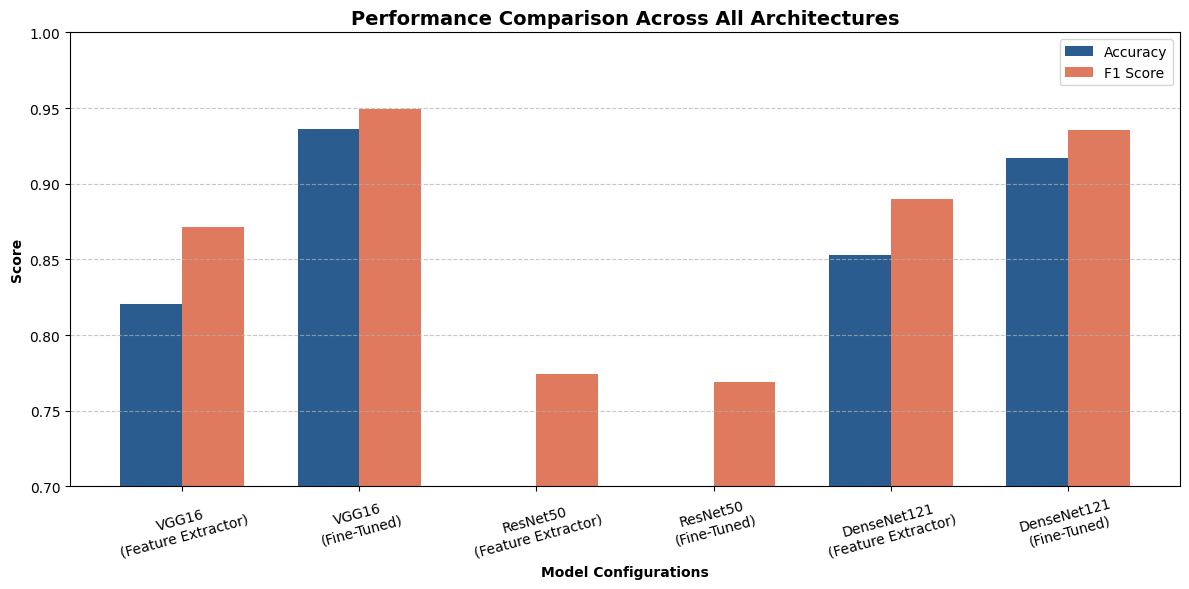

In [15]:
print("\n" + "=" * 90)
print("FINAL COMPARATIVE RESULTS")
print("=" * 90)
print(results_df.to_string(index=False))

# Visualization
plt.figure(figsize=(12, 6))
x = np.arange(len(results_df))
width = 0.35

plt.bar(x - width/2, results_df['Accuracy'], width, label='Accuracy', color='#2b5c8f')
plt.bar(x + width/2, results_df['F1'], width, label='F1 Score', color='#e07a5f')

plt.xlabel('Model Configurations', fontweight='bold')
plt.ylabel('Score', fontweight='bold')
plt.title('Performance Comparison Across All Architectures', fontsize=14, fontweight='bold')
plt.xticks(x, results_df['Model'] + '\n(' + results_df['Mode'] + ')', rotation=15)
plt.ylim(0.7, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()